# Who Gets Paid More? The Socio-Demographic Influences of Income
**Data Exploration and Preparation (DEP) - CCT College Dublin**  
**Author:** Rhuan Mendanha | **Topic:** Population and Society  
**Dataset:** UCI Adult / Census Income (Becker and Kohavi, 1996), The US Census of 1994 - 48,842 rows and 15 columns

### Research Questions
- **Q1.** How does the share of high earners (>50K) differ across the various social categories?
- **Q2.** Does education have the equal pay off for both genders?
- **Q3.** What is the relationship between age, work hours per week and income level?
- **Q4.** What attributes show the most correlation with income, and what unusual phenomena exist?

### Structure
1. Loading, Documentation and Cleaning of Data
2. Exploratory Data Analysis (variation, covariance, unusual phenomena)
3. Encoding (labels, ordinal, one-hot, PCA)

**Running Instructions:** keep `adult-all.csv` in the same folder as this notebook and select menu item *Run > Run All Cells*.

## Setup - libraries and chart style

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler

%matplotlib inline

In [2]:
# ---------- Setting up the graphs ----------
# I wanted all my graphs to have the same style so the project looks more organised.
# I chose colours that are easy to distinguish and kept the design simple
# so the information is easier to understand.

SAVE_FIGURES = False          # I only turn this on when I need to save graphs for my poster
FIG = Path("figures")        # This is the folder where I will save my graphs


class ps:
    # These are the colours I use throughout my graphs to keep everything consistent.
    BLUE = "#2a78d6"     # Used for the first group, such as <=50K or Female
    ORANGE = "#eb6834"   # Used for the second group, such as >50K or Male
    AQUA = "#1baf7a"
    INK = "#0b0b0b"
    INK2 = "#52514e"
    GRID = "#e4e3df"

    @staticmethod
    def apply():
        # Here I set up the general appearance of my graphs.
        # I adjusted the fonts, colours, grid lines and borders to make
        # the graphs look cleaner and easier to read.
        mpl.rcParams.update({
            "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
            "font.family": "DejaVu Sans", "font.size": 14,
            "axes.titlesize": 16, "axes.titleweight": "bold",
            "axes.titlelocation": "left", "axes.labelcolor": ps.INK2,
            "axes.edgecolor": ps.GRID, "axes.spines.top": False,
            "axes.spines.right": False, "axes.grid": True,
            "grid.color": ps.GRID, "grid.linewidth": 0.8,
            "xtick.color": ps.INK2, "ytick.color": ps.INK2,
            "text.color": ps.INK, "legend.frameon": False,
            "lines.linewidth": 2.2,
        })

    @staticmethod
    def save(fig, path):
        # I use this function whenever I finish a graph.
        # It displays the graph in my notebook and saves a copy if I need it later.
        if SAVE_FIGURES:
            FIG.mkdir(exist_ok=True)
            fig.savefig(path, facecolor="white")
        plt.show()


# I apply my graph settings here so all the graphs I create afterwards
# automatically follow the same style.
ps.apply()

## Part 1 - Data loading, characterisation and cleaning

Inferences from the dataset: UCI Adult / Census Income (Becker & Kohavi, 1996). The dataset consists of 48,842 rows and 15 columns and has been extracted from 1994 US Census Bureau database. 

Procedure:
1. Reading the raw CSV file (akin to removing the headers of the original file) and renaming the columns.
2. Description of the data set with respect to its size, features and data types.
3. Providing the solution for the missing values present in the data set (missing values defined as “?” in the original data).
4. Eliminating the duplicate records from the data file.
5. Identifying the outlier records by applying IQR rule and z-score.
6. Developing some features to use them in the Exploratory Data Analysis phase.
7. Saving the processed data set into the file – “adult_clean.csv” and the cleaning report in “cleaning_report.txt”.

### Paths

In [3]:
RAW = Path("adult-all.csv")   # This is the original dataset file, which I keep in the same folder as my notebook.

# The original dataset doesn't have column names, so I added them myself
# using the names provided by UCI. This makes it easier to work with the data
# and understand what each column represents.
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country",
    "income",
]

# I use this list to keep track of everything I do during the data cleaning process.
# This way, I can go back later and see what changes were made to the dataset.
report = []


def log(msg: str = "") -> None:
    # This function prints each message on screen and also saves it to my report.
    # This helps me keep a record of the steps I take while cleaning the data.
    print(msg)
    report.append(str(msg))

### 1. Load

In [4]:
# I load the original CSV file into a DataFrame and add the column names I defined earlier.
# I also remove extra spaces after commas so the data is easier to work with.
df = pd.read_csv(RAW, header=None, names=COLUMNS, skipinitialspace=True)


# I noticed that some text values can have extra spaces around them.
# I remove those spaces to avoid treating the same value as two different categories.
obj_cols = df.select_dtypes(exclude="number").columns
df[obj_cols] = df[obj_cols].apply(lambda s: s.str.strip())


# Some versions of the dataset have a full stop after the income values (e.g. '>50K.').
# I remove it so that all income labels follow the same format.
df["income"] = df["income"].str.replace(".", "", regex=False)

### 2. Characterisation

In [5]:
# ---------- 1. Understanding the original dataset ----------
# Before making any changes, I wanted to get a better idea of what my dataset looks like.
# Here I check its size, identify the numerical and categorical columns,
# and see how many different values each column contains.

log("=== 1. RAW DATA CHARACTERISATION ===")

# Shows how many rows and columns the dataset has.
log(f"Shape (rows, columns): {df.shape}")

# Separates the columns containing numbers from the categorical ones.
log(f"Numeric attributes    : {list(df.select_dtypes('number').columns)}")
log(f"Categorical attributes: {list(df.select_dtypes(exclude='number').columns)}")

# Checks how many unique values each column contains.
# This helps me understand the variety of information in the dataset.
log("Unique values per column:")
log(df.nunique().to_string())

# Adds an empty line to make the cleaning report easier to read.
log("")

=== 1. RAW DATA CHARACTERISATION ===
Shape (rows, columns): (48842, 15)
Numeric attributes    : ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical attributes: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']
Unique values per column:
age                  74
workclass             9
fnlwgt            28523
education            16
education_num        16
marital_status        7
occupation           15
relationship          6
race                  5
sex                   2
capital_gain        123
capital_loss         99
hours_per_week       96
native_country       42
income                2



### 3. Missing values


In [6]:
# ---------- 2. Checking and handling missing values ----------
# Some missing values in the original dataset are written as '?' instead of being empty.
# I replace them with NaN so pandas can recognise them properly and count them.

df = df.replace("?", np.nan)

# I check which columns have missing values and calculate how many there are.
# I also calculate the percentage of missing data in each column.
missing = df.isna().sum()
missing = missing[missing > 0]

log("=== 2. MISSING VALUES (before treatment) ===")
log(pd.DataFrame({"n_missing": missing,
                  "pct": (missing / len(df) * 100).round(2)}).to_string())

# Checks how many rows have at least one missing value.
log(f"Rows with at least one missing value: {df.isna().any(axis=1).sum()}")


# I wanted to check whether missing occupation values could affect my results.
# To do this, I compare the percentage of people earning over 50K
# between those with and without a recorded occupation.
occ_missing = df["occupation"].isna()
rate_missing = (df.loc[occ_missing, "income"] == ">50K").mean()
rate_present = (df.loc[~occ_missing, "income"] == ">50K").mean()

log(f">50K rate when occupation missing : {rate_missing:.3f}")
log(f">50K rate when occupation present : {rate_present:.3f}")

# I also check how many rows are missing both workclass and occupation.
both = (df["workclass"].isna() & df["occupation"].isna()).sum()
log(f"Rows where workclass AND occupation are both missing: {both}")
log("")


# ---------- Handling the missing values ----------
# Instead of deleting rows with missing information, I decided to keep them.
# Workclass and occupation are often missing together, so I label these values
# as 'Unknown' to avoid losing potentially useful information.
#
# Native country has very few missing values, so I replace them with the most
# common country in the dataset (the mode).

df["workclass"] = df["workclass"].fillna("Unknown")
df["occupation"] = df["occupation"].fillna("Unknown")

mode_country = df["native_country"].mode()[0]
df["native_country"] = df["native_country"].fillna(mode_country)

# I record the changes in my report and check if anything is still missing.
log(f"workclass/occupation NaN -> 'Unknown'; native_country NaN -> mode ('{mode_country}')")
log(f"Missing values after treatment: {int(df.isna().sum().sum())}")
log("")

=== 2. MISSING VALUES (before treatment) ===
                n_missing   pct
workclass            2799  5.73
occupation           2809  5.75
native_country        857  1.75
Rows with at least one missing value: 3620
>50K rate when occupation missing : 0.094
>50K rate when occupation present : 0.248
Rows where workclass AND occupation are both missing: 2799

workclass/occupation NaN -> 'Unknown'; native_country NaN -> mode ('United-States')
Missing values after treatment: 0



### 4. Duplicates

In [7]:
# ---------- 3. Checking and removing duplicate rows ----------
# I check if the dataset contains any completely duplicated rows.
# Duplicate records could affect my analysis, so I remove them to keep
# the dataset as accurate and consistent as possible.

n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

# I record how many duplicates were removed and check the new dataset size.
log("=== 3. DUPLICATES ===")
log(f"Exact duplicate rows removed: {n_dup}  ->  new shape {df.shape}")
log("")

=== 3. DUPLICATES ===
Exact duplicate rows removed: 52  ->  new shape (48790, 15)



### 4b. Logical inconsistencies

In [8]:
# ---------- 3b. Checking inconsistent records ----------
# I wanted to check if there were any records where the relationship and sex
# information did not match. For example, someone listed as a Husband but
# recorded as Female, or a Wife recorded as Male.
# I treat these cases as possible data-entry errors and remove them.

bad = ((df["relationship"] == "Husband") & (df["sex"] == "Female")) | \
      ((df["relationship"] == "Wife") & (df["sex"] == "Male"))

# I count the inconsistent records before removing them.
log("=== 3b. INCONSISTENT RECORDS ===")
log(f"Husband/Female or Wife/Male contradictions removed: {bad.sum()}")

# Removes the records that don't match and resets the row numbering.
df = df.loc[~bad].reset_index(drop=True)
log("")

=== 3b. INCONSISTENT RECORDS ===
Husband/Female or Wife/Male contradictions removed: 4



### 5. Outliers

In [9]:
# ---------- 4. Checking and handling outliers ----------
# Here I focus on the numerical columns to check if there are any unusual values.
# I use two different methods (IQR and Z-score) to identify values that are
# very far from the rest of the data.

num_cols = ["age", "fnlwgt", "education_num", "capital_gain",
            "capital_loss", "hours_per_week"]


# This function uses the IQR method to find values that are unusually low or high.
# It checks how far values are from the middle 50% of the data.
def iqr_outliers(s: pd.Series) -> int:
    """Number of values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR] (Tukey's rule)."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())


# This second function uses Z-scores to find values that are more than
# 3 standard deviations away from the average.
def z_outliers(s: pd.Series, thr: float = 3.0) -> int:
    """Number of values with |z-score| > thr."""
    z = (s - s.mean()) / s.std()
    return int((z.abs() > thr).sum())


# I put the results from both methods into one table.
# I also include the minimum and maximum values to get a better idea
# of the ranges in each numerical column.
out_tbl = pd.DataFrame({
    "IQR_outliers": {c: iqr_outliers(df[c]) for c in num_cols},
    "Z>3_outliers": {c: z_outliers(df[c]) for c in num_cols},
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
})
log("=== 4. OUTLIERS (before treatment) ===")
log(out_tbl.to_string())


# ---------- Handling capital_gain ----------
# I noticed that capital_gain contains the value 99999, which is a special
# value used by the original census data to represent very large amounts.
# I flag these records and replace the value with the highest genuine amount
# so it doesn't have too much influence on my analysis.

sentinel = df["capital_gain"] == 99999
log(f"capital_gain == 99999 (top-code sentinel): {sentinel.sum()} rows")

df["capital_gain_topcoded"] = sentinel.astype(int)
true_max = df.loc[~sentinel, "capital_gain"].max()
df.loc[sentinel, "capital_gain"] = true_max

log(f"  -> capped at largest real value {true_max}")


# ---------- Creating new capital features ----------
# Most people have zero capital_gain or capital_loss, which makes these columns
# very uneven. Instead of removing these values, I create some extra columns
# to make the information easier to use during the analysis.
#
# I calculate the net capital amount and use log1p to reduce the effect
# of extremely large values while keeping the original information useful.

df["capital_net"] = df["capital_gain"] - df["capital_loss"]
df["log_capital_gain"] = np.log1p(df["capital_gain"])
df["log_capital_loss"] = np.log1p(df["capital_loss"])

log(f"Share of zero capital_gain: {(df['capital_gain'] == 0).mean():.3f}")


# ---------- Handling working hours ----------
# Some people have unusually low or high working hours.
# I use the 1st and 99th percentiles to limit these extreme values.
# This keeps the records in the dataset without allowing extreme values
# to have too much influence on the results.

lo, hi = df["hours_per_week"].quantile([0.01, 0.99])
n_w = ((df["hours_per_week"] < lo) | (df["hours_per_week"] > hi)).sum()

df["hours_per_week"] = df["hours_per_week"].clip(lo, hi)

log(f"hours_per_week winsorised to [{lo:.0f}, {hi:.0f}] -> {n_w} values changed")


# ---------- Keeping other numerical columns ----------
# I decided to keep age as it is because its values are reasonable for this dataset.
# I also keep fnlwgt, but exclude it from the main analysis because it represents
# a survey sampling weight rather than a personal characteristic.

log("age kept (17-90 plausible); fnlwgt kept but excluded from analysis (sampling weight)")
log("")

=== 4. OUTLIERS (before treatment) ===
                IQR_outliers  Z>3_outliers    min      max
age                      215           185     17       90
fnlwgt                  1453           506  12285  1490400
education_num           1787           326      1       16
capital_gain            4035           331      0    99999
capital_loss            2282          2216      0     4356
hours_per_week         13485           681      1       99
capital_gain == 99999 (top-code sentinel): 244 rows
  -> capped at largest real value 41310
Share of zero capital_gain: 0.917
hours_per_week winsorised to [8, 80] -> 773 values changed
age kept (17-90 plausible); fnlwgt kept but excluded from analysis (sampling weight)



### 6. Helper features for EDA

In [10]:
# ---------- Creating new features ----------
# I create a new column called income_gt50k to make it easier to compare
# people earning above and below 50K. I convert the income categories into
# numbers (1 = above 50K and 0 = 50K or below), which is useful for analysis.

df["income_gt50k"] = (df["income"] == ">50K").astype(int)


# I also group people's ages into different ranges instead of looking
# at every individual age. This makes it easier to compare income patterns
# between different age groups.
df["age_group"] = pd.cut(df["age"], bins=[16, 25, 35, 45, 55, 65, 91],
                         labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"])


# ---------- Checking education information ----------
# I wanted to check if education and education_num contain the same information.
# If each education category always has the same numerical value, there is
# no need to treat them as completely separate pieces of information.
check = df.groupby("education")["education_num"].nunique().max()
log(f"education -> education_num is 1:1 mapping: {check == 1}")


# ---------- Converting columns into categories ----------
# Most of these columns contain repeated text values, such as occupation,
# workclass and marital status. I convert them to category types to make
# the dataset more efficient and easier to use when creating graphs.
for c in ["workclass", "marital_status", "occupation", "relationship",
          "race", "sex", "native_country", "income"]:
    df[c] = df[c].astype("category")

education -> education_num is 1:1 mapping: True


### 7. Keep the clean data set

In [11]:
# ---------- 5. Final check of the cleaned dataset ----------
# After completing the cleaning steps, I do one final check to see how
# the dataset looks. I check its size and the distribution of income
# to make sure everything is ready for the next stages of the project.

log("=== 5. CLEAN DATA ===")

# Checks the final number of rows and columns against the assignment requirements.
log(f"Final shape: {df.shape}  (requirement: >=3000 rows and >=7 columns)")

# Shows the percentage of people earning above and below 50K.
# This helps me understand how balanced the two income groups are.
log(f"Class balance: {df['income'].value_counts(normalize=True).round(3).to_dict()}")

# I create a separate copy of the cleaned dataset so I can use it
# in Parts 2 and 3 without having to repeat the cleaning process.
df_clean = df.copy()

=== 5. CLEAN DATA ===
Final shape: (48786, 21)  (requirement: >=3000 rows and >=7 columns)
Class balance: {'<=50K': 0.761, '>50K': 0.239}


## Part 2 - Exploratory Data Analysis (EDA)

Conducting exploratory data analysis on the cleansed Adult Census dataset.

Main questions (Population & Society):
  Q1. What is the distribution of high-income individuals (earning above 50k) based on gender, race, family status and relationship?            -> distribution
  Q2. How does education correlate between women and men in terms of income?      -> correlation
  Q3. What is the relationship between age/working hours and income?  -> correlation
  Q4. What are the most important variables when it comes to income, and if there are any interesting phenomena regarding data quality?        -> interesting phenomena

In [12]:
# ---------- Setting up Part 2 ----------
# I start by applying the same graph design from Part 1 so all my charts
# keep a consistent look throughout the project.

ps.apply()

# I use a fresh copy of the cleaned dataset from Part 1.
# This allows me to work on the analysis without changing my original clean data.
df = df_clean.copy()

# I convert categorical columns back to text so they are easier to work with
# when comparing groups and creating graphs.
for c in df.select_dtypes("category").columns:
    df[c] = df[c].astype(str)

# I also load the original dataset separately so I can compare some values
# before and after cleaning when needed.
raw = pd.read_csv(RAW, header=None,
                  skipinitialspace=True)

# I use this list to keep track of the results and notes from Part 2.
summary = []


def note(msg):
    # Prints each result and saves it so I can review the analysis later.
    print(msg)
    summary.append(str(msg))


def rate(by):
    # Calculates the percentage of people earning more than 50K
    # in each group. I use this function to compare income across
    # different categories without repeating the same calculation.
    return df.groupby(by, observed=True)["income_gt50k"].mean() * 100

### Figure 1 - data preparation: missing values and outliers

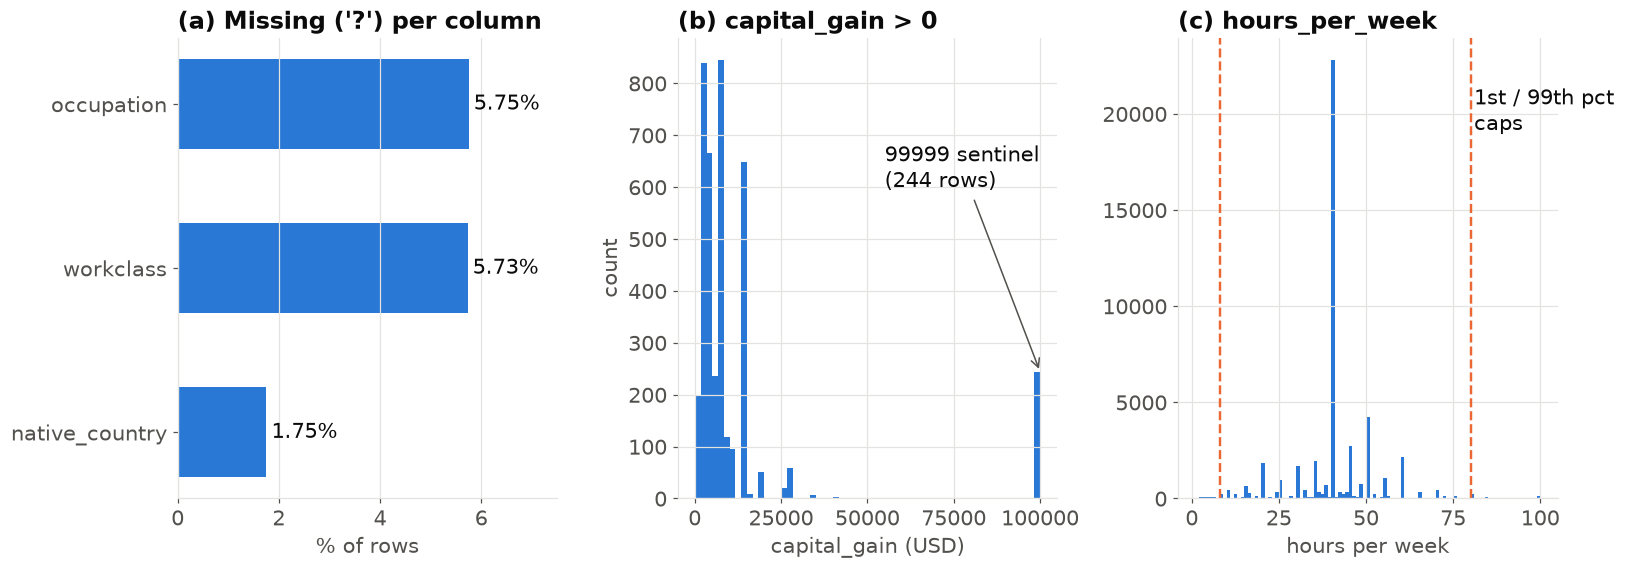

In [13]:
# ---------- Visualising the original data problems ----------
# I created three graphs side by side to show some of the main issues
# I found in the original dataset before cleaning it.
# This makes it easier to understand why certain cleaning steps were necessary.

fig, ax = plt.subplots(1, 3, figsize=(15, 5.4))


# (a) Checking missing values
# Here I calculate the percentage of missing values in each column.
# In the original dataset, missing information is represented by '?'.
# I only display columns that actually contain missing values.
miss = (raw == "?").mean().mul(100)
miss.index = ["age", "workclass", "fnlwgt", "education", "education_num",
              "marital_status", "occupation", "relationship", "race", "sex",
              "capital_gain", "capital_loss", "hours_per_week",
              "native_country", "income"]
miss = miss[miss > 0].sort_values()

# I use a horizontal bar chart so the columns with missing data
# are easier to compare, and add the percentages next to each bar.
ax[0].barh(miss.index, miss.values, color=ps.BLUE, height=0.55)
for i, v in enumerate(miss.values):
    ax[0].text(v + 0.1, i, f"{v:.2f}%", va="center", color=ps.INK)

ax[0].set_title("(a) Missing ('?') per column")
ax[0].set_xlabel("% of rows")
ax[0].set_xlim(0, 7.5)
ax[0].grid(axis="y", visible=False)


# (b) Looking at capital_gain
# I wanted to take a closer look at capital_gain because the value 99999
# appears as an unusual spike in the original data.
# This graph helps show why I treated that value separately during cleaning.
cg = raw[10]
ax[1].hist(cg[cg > 0], bins=60, color=ps.BLUE)

# I added an annotation to highlight the unusual 99999 value.
ax[1].annotate("99999 sentinel\n(244 rows)", xy=(99999, 244), xytext=(55000, 600),
               arrowprops=dict(arrowstyle="->", color=ps.INK2), color=ps.INK)

ax[1].set_title("(b) capital_gain > 0")
ax[1].set_xlabel("capital_gain (USD)")
ax[1].set_ylabel("count")


# (c) Looking at weekly working hours
# Here I check how working hours are distributed across the dataset.
# There is a large spike around 40 hours per week, which is quite common.
# I also mark the lower and upper limits used when I winsorised this column.
hw = raw[12]
ax[2].hist(hw, bins=range(1, 101), color=ps.BLUE)

# These dashed lines show the approximate 1st and 99th percentile limits.
for b in (8, 80):
    ax[2].axvline(b, color=ps.ORANGE, ls="--", lw=1.6)

ax[2].text(81, ax[2].get_ylim()[1] * 0.8, "1st / 99th pct\ncaps", color=ps.INK)
ax[2].set_title("(c) hours_per_week")
ax[2].set_xlabel("hours per week")


# I adjust the spacing so the three graphs fit together properly.
# Finally, I display the figure and save it if image exporting is enabled.
fig.tight_layout()
ps.save(fig, FIG / "fig1_data_preparation.png")

### Q1 - variation of income across social groups

=== Q1: % >50K by group ===
sex
Female    10.9
Male      30.4

race
Amer-Indian-Eskimo    11.7
Black                 12.1
Other                 12.3
White                 25.4
Asian-Pac-Islander    27.0

marital_status
Never-married             4.6
Separated                 6.5
Widowed                   8.4
Married-spouse-absent     9.3
Divorced                 10.1
Married-AF-spouse        37.8
Married-civ-spouse       44.6

relationship
Own-child          1.5
Other-relative     3.5
Unmarried          6.0
Not-in-family     10.2
Husband           44.9
Wife              46.9

workclass
Never-worked         0.0
Unknown              9.5
Without-pay          9.5
Private             21.8
State-gov           26.8
Self-emp-not-inc    27.9
Local-gov           29.6
Federal-gov         39.2
Self-emp-inc        55.4



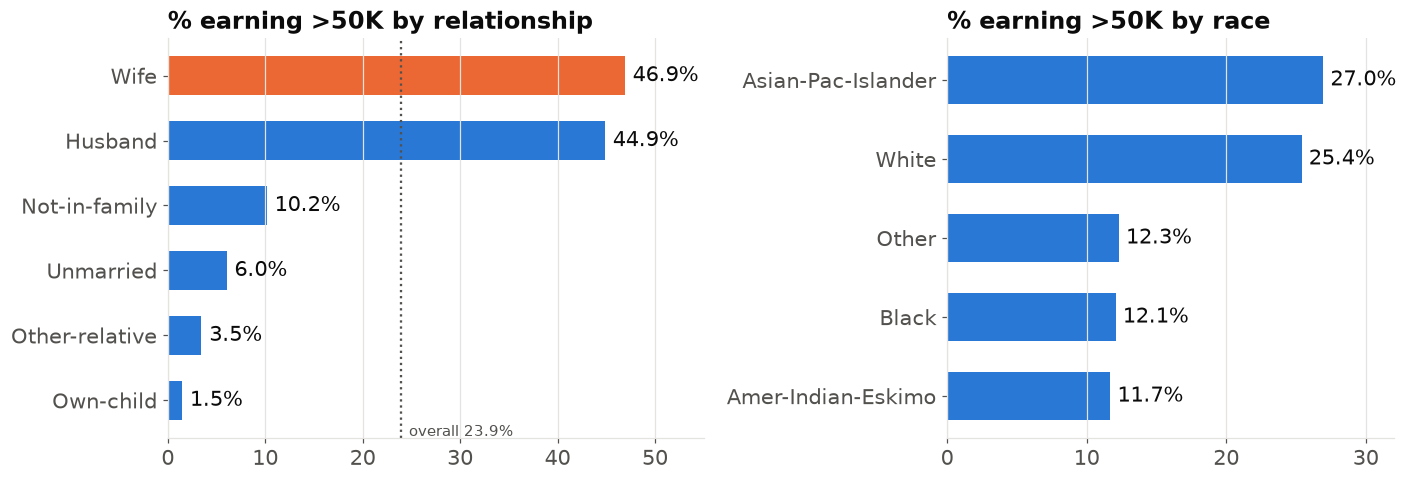

In [15]:
# ---------- Q1: Comparing income across different groups ----------
# I wanted to see how income levels differ between people with different
# backgrounds and personal characteristics.
# I calculate the percentage of people earning over 50K for each group
# so I can compare the results more easily.

note("=== Q1: % >50K by group ===")

# I check five different categories and record the results in my summary.
for col in ["sex", "race", "marital_status", "relationship", "workclass"]:
    note(rate(col).round(1).sort_values().to_string())
    note("")


# ---------- Creating graphs to compare the results ----------
# I created two graphs to make the differences easier to see.
# The first compares relationship status, while the second looks at race.

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6),
                       gridspec_kw={"width_ratios": [1.2, 1]})


# (a) Income by relationship status
# I calculate the percentage of people earning over 50K for each relationship group.
# I use a different colour for Wife to make that category stand out.
rel = rate("relationship").sort_values()
cols = [ps.ORANGE if r == "Wife" else ps.BLUE for r in rel.index]

ax[0].barh(rel.index, rel.values, color=cols, height=0.6)

# I add the percentages next to each bar so the results are easier to read.
for i, v in enumerate(rel.values):
    ax[0].text(v + 0.8, i, f"{v:.1f}%", va="center")

# This dotted line shows the overall percentage of people earning over 50K.
# It gives me a reference point to compare each relationship group against.
ax[0].axvline(df["income_gt50k"].mean() * 100, color=ps.INK2, ls=":", lw=1.5)
ax[0].text(df["income_gt50k"].mean() * 100 + 0.8, -0.55, "overall 23.9%",
           color=ps.INK2, fontsize=10)

ax[0].set_title("% earning >50K by relationship")
ax[0].set_xlim(0, 55)
ax[0].grid(axis="y", visible=False)


# (b) Income by race
# I use the same approach here to compare the percentage of people
# earning over 50K across the different race categories.
race = rate("race").sort_values()

ax[1].barh(race.index, race.values, color=ps.BLUE, height=0.6)

# I display the percentage next to each bar to make comparisons easier.
for i, v in enumerate(race.values):
    ax[1].text(v + 0.5, i, f"{v:.1f}%", va="center")

ax[1].set_title("% earning >50K by race")
ax[1].set_xlim(0, 32)
ax[1].grid(axis="y", visible=False)


# I adjust the spacing and display both graphs together.
# The figure is also saved if I have enabled image exporting.
fig.tight_layout()
ps.save(fig, FIG / "fig2_groups.png")

### Q2 - education x sex (covariation of a numeric and a categorical feature)

=== Q2: % >50K by years of education and sex ===
sex            Female  Male
education_num              
1                 0.0   1.8
2                 0.0   4.3
3                 3.1   6.1
4                 0.4   8.5
5                 2.3   6.7
6                 0.9   8.9
7                 1.7   7.0
8                 1.9   9.9
9                 6.5  20.3
10                7.0  26.4
11               12.7  32.4
12               13.7  33.6
13               21.1  50.4
14               34.3  64.5
15               47.7  78.9
16               56.6  76.3
Male/Female ratio at education_num 9-16: {9: 3.14, 10: 3.76, 11: 2.55, 12: 2.45, 13: 2.39, 14: 1.88, 15: 1.65, 16: 1.35}



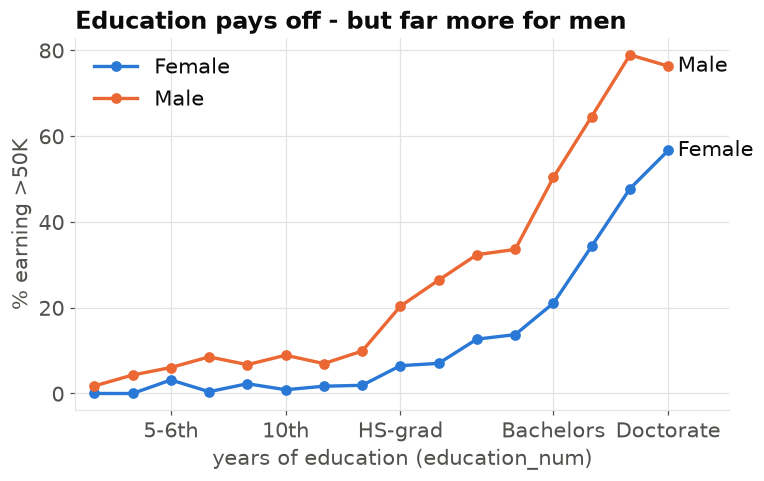

In [16]:
# ---------- Q2: Comparing income by education level and sex ----------
# Here I wanted to investigate whether having more years of education
# is linked to higher income, and whether the pattern is different
# between men and women.
# I calculate the percentage earning over 50K for each education level
# and separate the results by sex.

edu = rate(["education_num", "sex"]).unstack()

note("=== Q2: % >50K by years of education and sex ===")
note(edu.round(1).to_string())


# I calculate the ratio between male and female high earners for each
# education level from 9 to 16. This helps me compare the differences
# between the two groups at similar education levels.
ratio = (edu["Male"] / edu["Female"]).loc[9:16]
note(f"Male/Female ratio at education_num 9-16: {ratio.round(2).to_dict()}")
note("")


# ---------- Visualising the education and income relationship ----------
# I use a line chart to show how the percentage of people earning over 50K
# changes as their education level increases.
# Each line represents a different group, making the comparison easier.

fig, ax = plt.subplots(figsize=(7.2, 4.6))

for sex, c in [("Female", ps.BLUE), ("Male", ps.ORANGE)]:
    ax.plot(edu.index, edu[sex], color=c, marker="o", ms=6)
    ax.text(16.25, edu[sex].iloc[-1], sex, color=ps.INK, va="center")


# I replace the numerical education values with familiar qualification names
# so the graph is easier to understand.
ax.set_xticks([3, 6, 9, 13, 16])
ax.set_xticklabels(["5-6th", "10th", "HS-grad", "Bachelors", "Doctorate"])

ax.set_xlabel("years of education (education_num)")
ax.set_ylabel("% earning >50K")
ax.set_xlim(0.5, 17.6)

# I give the graph a title that highlights the pattern I wanted to investigate.
ax.set_title("Education pays off - but far more for men")
ax.legend(["Female", "Male"], loc="upper left")

# I finish by adjusting the layout and displaying the graph.
fig.tight_layout()
ps.save(fig, FIG / "fig3_education_sex.png")

### Q3 - age and hours worked vs income

=== Q3: % >50K by age group and sex ===
sex        Female  Male
age_group              
17-25         1.1   2.3
26-35        11.1  22.3
36-45        18.5  41.2
46-55        17.2  48.3
56-65        12.1  39.5
66+           7.5  25.9
=== Q3: % >50K by hours band ===
hours_band
<=20      6.8
21-34     7.1
35-39    15.7
40       21.3
41-49    34.6
50-59    44.2
60+      40.3
Mean hours: {'Female': 36.4, 'Male': 42.3}



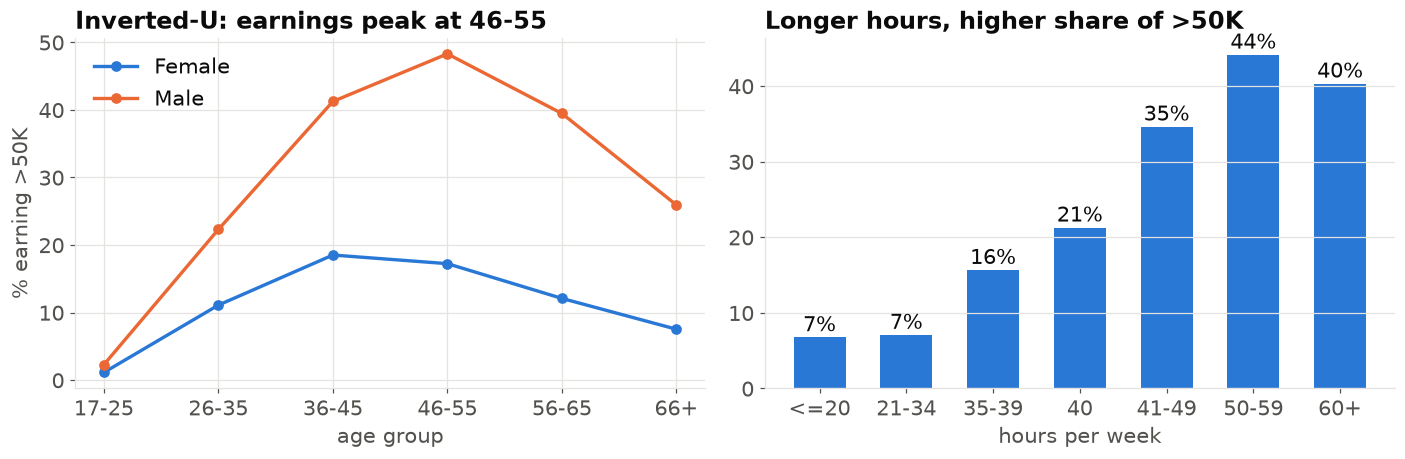

In [17]:
# ---------- Q3: Comparing income by age and working hours ----------
# I wanted to see how age and the number of hours worked per week
# relate to income. I also compare the results between men and women
# to see if there are any noticeable differences.

# First, I calculate the percentage of people earning over 50K
# for each age group, separated by sex.
age = rate(["age_group", "sex"]).unstack()

# I arrange the age groups in the correct order so they appear
# from youngest to oldest in the graph.
order = ["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]
age = age.loc[order]


# I create new groups based on the number of hours people work each week.
# This makes it easier to compare income between people working different hours.
df["hours_band"] = pd.cut(df["hours_per_week"], [0, 20, 34, 39, 40, 49, 59, 80],
                          labels=["<=20", "21-34", "35-39", "40", "41-49",
                                  "50-59", "60+"])

# I calculate the percentage of people earning over 50K in each working-hours group.
hrs = rate("hours_band")


# I record the results so I can compare the different groups later.
note("=== Q3: % >50K by age group and sex ===")
note(age.round(1).to_string())

note("=== Q3: % >50K by hours band ===")
note(hrs.round(1).to_string())

# I also check the average number of working hours for men and women.
note(f"Mean hours: {df.groupby('sex')['hours_per_week'].mean().round(1).to_dict()}")
note("")


# ---------- Visualising age, sex and working hours ----------
# I created two graphs to make the results easier to understand.
# The first looks at age and income, while the second compares
# income levels across different working-hours groups.

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))


# (a) Income by age group and sex
# I use two lines to compare how income changes across age groups
# for men and women.
for sex, c in [("Female", ps.BLUE), ("Male", ps.ORANGE)]:
    ax[0].plot(order, age[sex], color=c, marker="o", ms=6, label=sex)

ax[0].set_title("Inverted-U: earnings peak at 46-55")
ax[0].set_ylabel("% earning >50K")
ax[0].set_xlabel("age group")
ax[0].legend()


# (b) Income by working hours
# Here I use a bar chart to show how the percentage of people
# earning over 50K changes depending on how many hours they work.
ax[1].bar(hrs.index.astype(str), hrs.values, color=ps.BLUE, width=0.6)

# I add the percentages above each bar so the values are easy to compare.
for i, v in enumerate(hrs.values):
    ax[1].text(i, v + 0.8, f"{v:.0f}%", ha="center")

ax[1].set_title("Longer hours, higher share of >50K")
ax[1].set_xlabel("hours per week")
ax[1].grid(axis="x", visible=False)


# I adjust the layout and display both graphs together.
fig.tight_layout()
ps.save(fig, FIG / "fig4_age_hours.png")

### Q4 - strength of association with income (all features)

=== Q4: association with income (Pearson r for numeric, Cramer's V for categorical) ===
native_country      0.092
race                0.100
log_capital_loss    0.138
workclass           0.181
sex                 0.215
age                 0.230
hours_per_week      0.234
log_capital_gain    0.288
education_num       0.333
occupation          0.350
marital_status      0.448
relationship        0.454
=== Correlation matrix (numeric) ===
                   age  education_num  hours_per_week  log_capital_gain  log_capital_loss  income_gt50k
age               1.00           0.03            0.07              0.12              0.05          0.23
education_num     0.03           1.00            0.15              0.13              0.08          0.33
hours_per_week    0.07           0.15            1.00              0.09              0.05          0.23
log_capital_gain  0.12           0.13            0.09              1.00             -0.07          0.29
log_capital_loss  0.05           0.08      

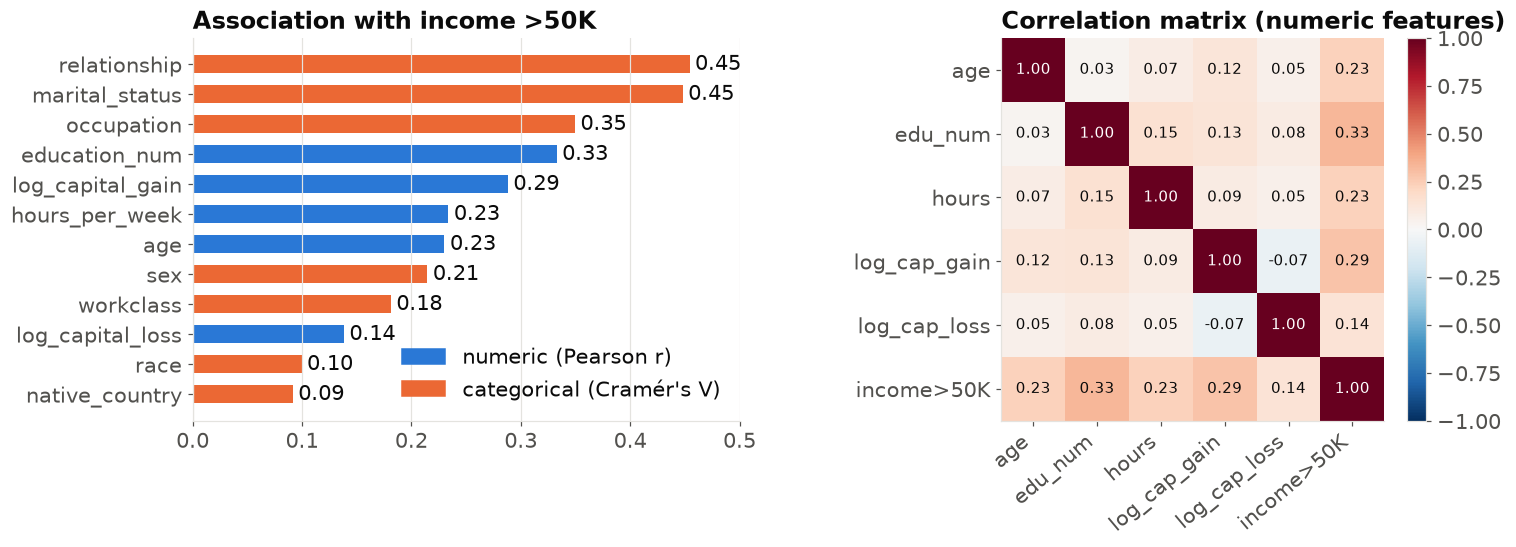

Part 2 finished.


In [18]:
# ---------- Q4: Measuring the relationship between features and income ----------
# For this part, I wanted to find out which features have the strongest
# relationship with income. I use different methods depending on the type
# of data: Pearson correlation for numerical columns and Cramér's V
# for categorical columns.


# This function calculates Cramér's V, which helps me measure how strongly
# two categorical variables are related. I use it for columns such as
# relationship, occupation, sex and workclass.
def cramers_v(x, y):
    """Bias-corrected Cramer's V between two categorical series."""
    tbl = pd.crosstab(x, y)
    chi2 = chi2_contingency(tbl, correction=False)[0]
    n = tbl.values.sum()
    r, k = tbl.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(kc - 1, rc - 1))


# I separate the numerical and categorical features so I can apply
# the correct correlation method to each group.
num = ["age", "education_num", "hours_per_week", "log_capital_gain",
       "log_capital_loss"]

cat = ["relationship", "marital_status", "occupation", "sex", "workclass",
       "race", "native_country"]


# I calculate the relationship between each feature and income.
# This gives me one list of results that I can sort to see which features
# have the strongest association with people earning over 50K.
assoc = pd.Series({c: df[c].corr(df["income_gt50k"]) for c in num} |
                  {c: cramers_v(df[c], df["income"]) for c in cat})

assoc = assoc.sort_values()

note("=== Q4: association with income (Pearson r for numeric, Cramer's V for categorical) ===")
note(assoc.round(3).to_string())


# I also create a correlation matrix for the numerical features.
# This allows me to check how the numerical columns relate to each other,
# as well as how they relate to the income target.
corr = df[num + ["income_gt50k"]].corr()

note("=== Correlation matrix (numeric) ===")
note(corr.round(2).to_string())


# ---------- Visualising the correlation results ----------
# I use two graphs to present the results.
# The first compares the strength of the relationship between each feature
# and income. The second gives a closer look at the numerical correlations.

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2),
                       gridspec_kw={"width_ratios": [1, 1.05]})


# (a) Association between features and income
# I use different colours to separate numerical features from categorical ones.
colors = [ps.BLUE if c in num else ps.ORANGE for c in assoc.index]

ax[0].barh(assoc.index, assoc.values, color=colors, height=0.6)

# I add the association values next to each bar to make comparisons easier.
for i, v in enumerate(assoc.values):
    ax[0].text(v + 0.005, i, f"{v:.2f}", va="center")

ax[0].set_title("Association with income >50K")
ax[0].set_xlim(0, 0.5)
ax[0].grid(axis="y", visible=False)

# This legend explains what each colour represents.
ax[0].legend(handles=[Patch(color=ps.BLUE, label="numeric (Pearson r)"),
                      Patch(color=ps.ORANGE, label="categorical (Cramér's V)")],
             loc="lower right")


# (b) Numerical correlation matrix
# I use a heatmap to show how strongly the numerical features are related.
# The colours help me spot positive and negative relationships more easily.
labels = ["age", "edu_num", "hours", "log_cap_gain", "log_cap_loss", "income>50K"]

im = ax[1].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)

ax[1].set_xticks(range(len(labels)), labels, rotation=40, ha="right")
ax[1].set_yticks(range(len(labels)), labels)
ax[1].grid(False)

# I display the actual correlation values inside each square
# so I don't have to rely only on the colours to understand the results.
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax[1].text(j, i, f"{v:.2f}", ha="center", va="center",
                   color="white" if abs(v) > 0.6 else ps.INK, fontsize=10)

ax[1].set_title("Correlation matrix (numeric features)")

# Adds a colour scale to help explain the correlation values.
fig.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04)

# I finish by adjusting the layout and displaying both graphs.
fig.tight_layout()
ps.save(fig, FIG / "fig5_association.png")


# Confirms that all the analysis and graphs in Part 2 are finished.
print("Part 2 finished.")